# Step 2 — PPO: the three fixes, one at a time

Same game as step 1, same target. Two players, accuracies 0.4 and 0.8, and the exact
answer is still $1/3$ and $2/3$.

**The game is held fixed on purpose.** Only the algorithm changes, so if the numbers
move, the algorithm moved them. Change the game at the same time and you learn nothing
about either.

| REINFORCE's problem | PPO's fix | Where it appears below |
|---|---|---|
| Uses total episode reward, so a good move in a lost episode looks bad | An **advantage** — was this better than expected *from here* | needs a value network |
| Each episode used once, then thrown away | Reuse the batch for several **epochs** | the epoch loop |
| Reusing it naively breaks, because the policy has moved | **Clip** the update | the ratio and `torch.clamp` |

The hope is the *same answer* as step 1 from *fewer* episodes. A late section measures
that against REINFORCE at matched budgets rather than asserting it, and on this duel the
answer is that it does not: the duel is too easy to separate the two.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from gruel_env import GruelEnv, N_ACTIONS

SEED = 0
GAME_SEED = 1000 + SEED
TORCH_SEED = 2000 + SEED

torch.manual_seed(TORCH_SEED)
torch.set_num_threads(1)          # tiny network; threads only add contention

print("torch", torch.__version__)

torch 2.2.2


## The target, again computed before training

Unchanged from step 1, and restated here because this folder stands alone.

In [2]:
WEAK_ACCURACY = 0.4
STRONG_ACCURACY = 0.8

exact_weak = WEAK_ACCURACY / (WEAK_ACCURACY + STRONG_ACCURACY)
exact_strong = STRONG_ACCURACY / (WEAK_ACCURACY + STRONG_ACCURACY)

print("exact survival, weak   (0.4):", round(exact_weak, 4))
print("exact survival, strong (0.8):", round(exact_strong, 4))

exact survival, weak   (0.4): 0.3333
exact survival, strong (0.8): 0.6667


## Fix 1 needs a second network

The advantage asks "was this action better than what I expected from this position?"
Answering it needs an estimate of what to expect — a **value**.

So there are now two heads: the **actor** picks actions, the **critic** scores
positions. They are kept as two separate little networks sharing no weights. Many real
implementations share a trunk, and the reason not to here is step 3: there the critic
is given the *whole game state* while the actor still sees only its own four numbers.
Once the two take different inputs a shared trunk is impossible, so keeping them
separate now makes step 3 a smaller change rather than a rewrite.

In [3]:
OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64


class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        # The actor: observation in, one score per action out.
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)

        # The critic: observation in, ONE number out — how good is this position.
        self.critic_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)

        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.actor_first(observation)
        hidden = self.activation(hidden)
        logits = self.actor_second(hidden)
        return logits

    def value(self, observation):
        hidden = self.critic_first(observation)
        hidden = self.activation(hidden)
        value = self.critic_second(hidden)
        # Drop the trailing size-1 dimension so values line up with rewards.
        return value.squeeze(-1)


model = ActorCritic()

total_parameters = 0
for parameter in model.parameters():
    total_parameters = total_parameters + parameter.numel()
print("parameters:", total_parameters, "(step 1 had 515)")

parameters: 900 (step 1 had 515)


## What the critic is for, before it is trained

Untrained, its output is meaningless. Worth printing anyway so the *shape* of what it
does is clear: one number per observation.

In [4]:
example = torch.tensor([[0.4, 0.8, 0.8, 1.0],
                        [0.8, 0.4, 0.4, 1.0]])
print("observations:", tuple(example.shape))
print("values:      ", model.value(example).detach().numpy().round(4))
print("logits:      ", model.action_logits(example).detach().numpy().round(4))

observations: (2, 4)
values:       [-0.4127 -0.4534]
logits:       [[-0.002  -0.197  -0.3148]
 [ 0.2222  0.0119 -0.2112]]


## Collecting a batch

Step 1 collected one episode and updated. Here we collect many episodes first,
recording everything the update will need: what was seen, what was done, how likely
that action was **at the time**, what the critic thought, and what actually happened.

That "at the time" log-probability is the one genuinely new bookkeeping item. Clipping
compares the *current* policy to the policy that collected the data, so the old value
has to be stored.

In [5]:
def collect_batch(model, game, episodes):
    observations = []
    actions = []
    old_log_probabilities = []
    values = []
    returns = []
    episode_winners = []

    for _ in range(episodes):
        game.reset()

        episode_observations = []
        episode_actions = []
        episode_log_probabilities = []
        episode_values = []
        episode_actors = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            observation_tensor = torch.from_numpy(observation)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(observation_tensor)

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations.append(observation)
            episode_actions.append(int(action))
            episode_log_probabilities.append(float(distribution.log_prob(action)))
            episode_values.append(float(value))
            episode_actors.append(actor)

            game.step(int(action))

        if len(game.order) == 1:
            winner = game.order[0]
        else:
            winner = None

        # Each decision's return is whether its OWN owner went on to win. This is
        # per-agent credit, and it is what step 3 has to generalise.
        for index in range(len(episode_actions)):
            if episode_actors[index] == winner:
                returns.append(1.0)
            else:
                returns.append(0.0)

        observations.extend(episode_observations)
        actions.extend(episode_actions)
        old_log_probabilities.extend(episode_log_probabilities)
        values.extend(episode_values)

        # Who won this episode, recorded ONCE per episode — a different length from the
        # per-decision arrays above, on purpose. A winner survives longer and so makes
        # more decisions, so counting decisions would weight winning episodes too
        # heavily.
        if winner is None:
            episode_winners.append(None)
        else:
            episode_winners.append(float(game.accuracies[winner]))

    batch = {
        "observations": torch.tensor(np.array(observations), dtype=torch.float32),
        "actions": torch.tensor(actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(old_log_probabilities, dtype=torch.float32),
        "values": torch.tensor(values, dtype=torch.float32),
        "returns": torch.tensor(returns, dtype=torch.float32),
        "episode_winners": episode_winners,
    }
    return batch


game = GruelEnv(n=2, reward="terminal", seating="ranked", seed=GAME_SEED)
batch = collect_batch(model, game, episodes=64)
print("decisions collected:", len(batch["actions"]))
print("episodes collected: ", len(batch["episode_winners"]))
for name, value in batch.items():
    if name == "episode_winners":
        print("  " + name.ljust(24) + " list of " + str(len(value)))
    else:
        print("  " + name.ljust(24) + " " + str(tuple(value.shape)))

decisions collected: 150
episodes collected:  64
  observations             (150, 4)
  actions                  (150,)
  old_log_probabilities    (150,)
  values                   (150,)
  returns                  (150,)
  episode_winners          list of 64


## Fix 1: the advantage

The advantage is what actually happened minus what the critic expected:

$$A = R - V(s)$$

So an action is judged against its own position, not against the whole game. A good
move in a lost episode can now have a positive advantage.

**This is where the loss becomes able to go negative**, which step 1's could not — but
not yet. The critic here is untrained, so its output is arbitrary: whatever the random
initialisation happens to produce, the same for every position. If that arbitrary value
is **negative**, then $A = R - V(s)$ is positive even when the return is zero, and every
advantage in the batch comes out positive. Watch for that below.

Either way the advantage carries no more information than REINFORCE's return did while
the critic is untrained, which is the reason the critic has to be fitted. The sign
structure appears further down, once it has been.

Then it is **standardised** — mean zero, unit spread. That is not part of the idea, it
is a practical step that keeps update sizes stable. Real implementations all do it.

In [6]:
advantages = batch["returns"] - batch["values"]
print("raw advantage    mean %.4f   std %.4f" % (advantages.mean(), advantages.std()))
print("critic output    mean %.4f   min %.4f   max %.4f"
      % (batch["values"].mean(), batch["values"].min(), batch["values"].max()))
print("  untrained, so this number means nothing yet — it is whatever the random")
print("  initialisation produced, and its SIGN is what decides the advantage signs")

negative = int((advantages < 0).sum())
print("negative advantages: %d of %d  (share %.3f)"
      % (negative, len(advantages), negative / len(advantages)))

standardised = (advantages - advantages.mean()) / (advantages.std() + 1e-8)
print("standardised     mean %.4f   std %.4f" % (standardised.mean(), standardised.std()))

raw advantage    mean 1.1255   std 0.4719
critic output    mean -0.4322   min -0.4534   max -0.4127
  untrained, so this number means nothing yet — it is whatever the random
  initialisation produced, and its SIGN is what decides the advantage signs
negative advantages: 0 of 150  (share 0.000)
standardised     mean 0.0000   std 1.0000


## Fix 3: the ratio and the clip

Taking fix 3 before fix 2, because fix 2 is what makes fix 3 necessary.

The ratio is how much more likely the action is *now* than when it was collected:

$$r = \frac{\pi_\text{new}(a \mid s)}{\pi_\text{old}(a \mid s)}
     = \exp\big(\log \pi_\text{new} - \log \pi_\text{old}\big)$$

Computed as a difference of logs and then exponentiated, which is the standard way —
subtracting logs is better behaved numerically than dividing small probabilities.

Immediately after collecting, nothing has changed, so every ratio is exactly 1.

In [7]:
def policy_ratio(model, batch):
    logits = model.action_logits(batch["observations"])
    distribution = torch.distributions.Categorical(logits=logits)
    new_log_probabilities = distribution.log_prob(batch["actions"])
    log_ratio = new_log_probabilities - batch["old_log_probabilities"]
    return torch.exp(log_ratio), distribution


ratio, _ = policy_ratio(model, batch)
print("ratios before any update: min %.4f  max %.4f  (should both be 1.0000)"
      % (ratio.min(), ratio.max()))

ratios before any update: min 1.0000  max 1.0000  (should both be 1.0000)


The clipped objective takes the **worse** of two options: the plain ratio-weighted
advantage, and one where the ratio is held inside $[1-\epsilon,\ 1+\epsilon]$.

Taking the worse of the two is the whole trick. If moving further would look good, the
clipped version caps the gain, so there is no reward for moving far. If moving further
looks bad, the unclipped version keeps that penalty. So the policy can be pulled back
but not pushed away.

In [8]:
CLIP = 0.2


def clipped_objective(ratio, advantage, clip=CLIP):
    unclipped = ratio * advantage
    clipped = torch.clamp(ratio, 1 - clip, 1 + clip) * advantage
    # Minimum, then negated, because optimisers minimise.
    return -torch.min(unclipped, clipped).mean()


for drifted_ratio in [0.5, 0.8, 1.0, 1.2, 1.5]:
    ratio_example = torch.tensor([drifted_ratio])
    good = clipped_objective(ratio_example, torch.tensor([1.0]))
    bad = clipped_objective(ratio_example, torch.tensor([-1.0]))
    print("  ratio %.1f   advantage +1 -> loss %+.3f    advantage -1 -> loss %+.3f"
          % (drifted_ratio, float(good), float(bad)))

  ratio 0.5   advantage +1 -> loss -0.500    advantage -1 -> loss +0.800
  ratio 0.8   advantage +1 -> loss -0.800    advantage -1 -> loss +0.800
  ratio 1.0   advantage +1 -> loss -1.000    advantage -1 -> loss +1.000
  ratio 1.2   advantage +1 -> loss -1.200    advantage -1 -> loss +1.200
  ratio 1.5   advantage +1 -> loss -1.200    advantage -1 -> loss +1.500


Read the table above: with a **positive** advantage the loss stops improving past ratio
1.2 — that is the cap. With a **negative** advantage it keeps getting worse as the ratio
grows, so there is always pressure back. Asymmetric on purpose.

## Fix 2: several epochs over the same batch

Now the batch can be reused, because clipping makes reuse safe. Each epoch walks the
data in shuffled minibatches.

The critic is trained at the same time, on how wrong its value estimate was. And an
**entropy bonus** is subtracted to discourage collapsing onto one action too early —
without it a policy can commit before it has explored.

The update also reports **how often the clip actually binds**, which is the number to
watch. Never binding means the updates are too small to need it; binding constantly
means the learning rate is too high.

In [9]:
EPOCHS = 4
MINIBATCH_SIZE = 64
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01


def ppo_update(model, optimiser, batch, rng, entropy_coefficient=ENTROPY_COEFFICIENT):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    clipped_count = 0
    total_count = 0
    policy_loss_value = 0.0
    value_loss_value = 0.0
    entropy_value = 0.0

    for epoch in range(EPOCHS):
        rng.shuffle(order)

        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            minibatch = {
                "observations": batch["observations"][index],
                "actions": batch["actions"][index],
                "old_log_probabilities": batch["old_log_probabilities"][index],
                "returns": batch["returns"][index],
            }
            minibatch_advantages = advantages[index]

            ratio, distribution = policy_ratio(model, minibatch)

            # How many ratios have drifted outside the clip window. Counted before the
            # step, so it describes the update about to be made.
            outside = (ratio < 1 - CLIP) | (ratio > 1 + CLIP)
            clipped_count = clipped_count + int(outside.sum())
            total_count = total_count + int(ratio.numel())

            policy_loss = clipped_objective(ratio, minibatch_advantages)

            predicted_value = model.value(minibatch["observations"])
            value_loss = ((predicted_value - minibatch["returns"]) ** 2).mean()

            entropy = distribution.entropy().mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - entropy_coefficient * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()

            policy_loss_value = float(policy_loss)
            value_loss_value = float(value_loss)
            entropy_value = float(entropy)

    if total_count > 0:
        clip_fraction = clipped_count / total_count
    else:
        clip_fraction = 0.0

    return {
        "policy_loss": policy_loss_value,
        "value_loss": value_loss_value,
        "entropy": entropy_value,
        "clip_fraction": clip_fraction,
    }

## Training

## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [10]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step2_ppo.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [11]:
UPDATES = 40
EPISODES_PER_UPDATE = 64


def train(model, updates=UPDATES, episodes_per_update=EPISODES_PER_UPDATE,
          learning_rate=0.003, game_seed=GAME_SEED,
          entropy_coefficient=ENTROPY_COEFFICIENT):
    game = GruelEnv(n=2, reward="terminal", seating="ranked", seed=game_seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate)
    rng = np.random.default_rng(SEED)

    history_episodes = []
    history_weak = []
    history_clip = []
    history_policy_loss = []
    episodes_done = 0

    for update in range(updates):
        batch = collect_batch(model, game, episodes_per_update)
        statistics = ppo_update(model, optimiser, batch, rng,
                                entropy_coefficient=entropy_coefficient)
        episodes_done = episodes_done + episodes_per_update

        weak_wins = 0
        episodes_counted = 0
        for winner_accuracy in batch["episode_winners"]:
            episodes_counted = episodes_counted + 1
            if winner_accuracy is not None and abs(winner_accuracy - WEAK_ACCURACY) < 1e-6:
                weak_wins = weak_wins + 1

        if episodes_counted > 0:
            history_episodes.append(episodes_done)
            history_weak.append(weak_wins / episodes_counted)
            history_clip.append(statistics["clip_fraction"])
            history_policy_loss.append(statistics["policy_loss"])

    return history_episodes, history_weak, history_clip, history_policy_loss

In [12]:
def reinforce_settings(episodes, torch_seed, game_seed, seconds):
    return {
        "algorithm": "REINFORCE, one shared policy, no critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": "none",
        "game": {"n_players": 2, "reward": "terminal", "seating": "ranked", "accuracies_ascending": accuracies_ascending(2), "stagnation_rounds": 10},
        "training": {"episodes": episodes, "batch_size": 32, "optimiser": "Adam",
                     "learning_rate": 0.01, "discount": 1.0,
                     "loss": "minus log-probability times the episode reward, averaged over a batch"},
        "seeds": {"torch": torch_seed, "training_game": game_seed},
        "seconds": round(seconds, 1),
        "seconds_cover": "training only",
    }


def ppo_duel_settings(updates, torch_seed, game_seed, entropy_coefficient, seconds):
    return {
        "algorithm": "PPO, one shared actor and a critic that sees the actor's four numbers",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": "the same four numbers as the actor: 4 inputs",
        "game": {"n_players": 2, "reward": "terminal", "seating": "ranked", "accuracies_ascending": accuracies_ascending(2), "stagnation_rounds": 10},
        "training": {"updates": updates, "episodes_per_update": EPISODES_PER_UPDATE,
                     "training_episodes": updates * EPISODES_PER_UPDATE, "optimiser": "Adam",
                     "learning_rate": 0.003, "clip": CLIP, "epochs": EPOCHS,
                     "minibatch_size": MINIBATCH_SIZE, "value_coefficient": VALUE_COEFFICIENT,
                     "entropy_coefficient": entropy_coefficient, "discount": 1.0},
        "seeds": {"torch": torch_seed, "training_game": game_seed, "minibatch_shuffle": SEED},
        "seconds": round(seconds, 1),
        "seconds_cover": "training only",
    }


torch.manual_seed(TORCH_SEED)
model = ActorCritic()
started = time.time()
episodes_axis, weak_survival, clip_fractions, policy_losses = train(model)
save_model(model, "n2_ranked_terminal_ppo_u%d_seed%d" % (UPDATES, SEED),
           ppo_duel_settings(UPDATES, TORCH_SEED, GAME_SEED, ENTROPY_COEFFICIENT, time.time() - started))

print("episodes of self-play used:", episodes_axis[-1])
print("target", round(exact_weak, 4))
print("last five measurements:", [round(v, 4) for v in weak_survival[-5:]])

episodes of self-play used: 2560
target 0.3333
last five measurements: [0.2188, 0.2656, 0.3594, 0.4219, 0.4062]


## What to watch: does the clip bind, and does the loss go negative?

The first question the README asks. The second one now has an answer the untrained
critic could not give: collect a fresh batch with the **trained** critic and look at the
advantage signs again.

In [13]:
trained_batch = collect_batch(model, game, episodes=64)
trained_advantages = trained_batch["returns"] - trained_batch["values"]
trained_negative = int((trained_advantages < 0).sum())

print("with the TRAINED critic:")
print("  critic output    mean %.4f   min %.4f   max %.4f"
      % (trained_batch["values"].mean(), trained_batch["values"].min(),
         trained_batch["values"].max()))
print("  negative advantages: %d of %d  (share %.3f)"
      % (trained_negative, len(trained_advantages),
         trained_negative / len(trained_advantages)))
print("  earlier, untrained, the share was %.3f" % (negative / len(advantages)))
print()

# The mechanism, stated so it can be checked rather than believed: a decision in a lost
# episode has R = 0, so its advantage is -V(s). That is negative for exactly as long as
# the critic's prediction stays above zero.
lowest_value = float(trained_batch["values"].min())
if lowest_value > 0:
    print("  the critic's LOWEST prediction is %.4f, above zero, so every decision in a"
          % lowest_value)
    print("  lost episode scores negative and every one in a won episode scores positive")
else:
    print("  the critic predicts %.4f somewhere, at or below zero, so a lost episode can"
          % lowest_value)
    print("  still score non-negative there")

print()
print("  That signed advantage is the point of the baseline, and it is what makes the")
print("  policy loss able to go negative too.")
print()

print("clip fraction — share of ratios outside [%.1f, %.1f]:" % (1 - CLIP, 1 + CLIP))
print("  first update: %.4f" % clip_fractions[0])
print("  mean:         %.4f" % (sum(clip_fractions) / len(clip_fractions)))
print("  largest:      %.4f" % max(clip_fractions))
print()

negative_losses = 0
for loss_value in policy_losses:
    if loss_value < 0:
        negative_losses = negative_losses + 1
print("policy loss: %d of %d updates ended negative (share %.3f)"
      % (negative_losses, len(policy_losses), negative_losses / len(policy_losses)))
print("  a negative loss is correct here — the advantage is signed, unlike step 1's reward")

with the TRAINED critic:
  critic output    mean 0.7093   min 0.5669   max 0.8432
  negative advantages: 17 of 97  (share 0.175)
  earlier, untrained, the share was 0.000

  the critic's LOWEST prediction is 0.5669, above zero, so every decision in a
  lost episode scores negative and every one in a won episode scores positive

  That signed advantage is the point of the baseline, and it is what makes the
  policy loss able to go negative too.

clip fraction — share of ratios outside [0.8, 1.2]:
  first update: 0.3617
  mean:         0.0471
  largest:      0.3617

policy loss: 22 of 40 updates ended negative (share 0.550)
  a negative loss is correct here — the advantage is signed, unlike step 1's reward


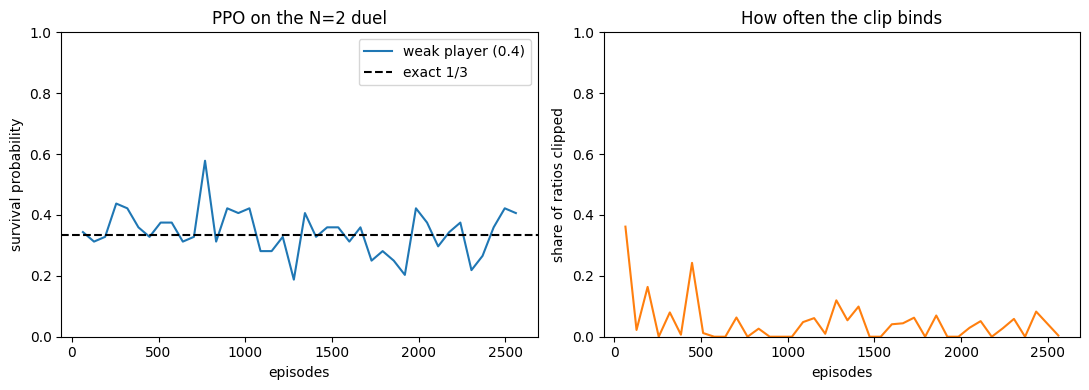

In [14]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

left.plot(episodes_axis, weak_survival, label="weak player (0.4)")
left.axhline(exact_weak, linestyle="--", color="black", label="exact 1/3")
left.set_xlabel("episodes")
left.set_ylabel("survival probability")
left.set_title("PPO on the N=2 duel")
left.set_ylim(0, 1)
left.legend()

right.plot(episodes_axis, clip_fractions, color="tab:orange")
right.set_xlabel("episodes")
right.set_ylabel("share of ratios clipped")
right.set_title("How often the clip binds")
right.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## Evaluate properly, same as step 1

Same 20,000 episodes with training off, so the number is directly comparable.

In [15]:
def evaluate(model, episodes=20000, game_seed=5000):
    game = GruelEnv(n=2, reward="terminal", seating="ranked", seed=game_seed)
    survivals = {WEAK_ACCURACY: 0, STRONG_ACCURACY: 0}
    completed = 0

    with torch.no_grad():
        for _ in range(episodes):
            game.reset()
            for acting_agent in game.agent_iter():
                observation, reward, termination, truncation, info = game.last()

                # A finished agent is handed to us one last time, so PettingZoo can
                # retire it. Stepping with None is how we say 'nothing to do here'.
                if termination or truncation:
                    game.step(None)
                    continue

                observation_tensor = torch.from_numpy(observation)
                logits = model.action_logits(observation_tensor)
                distribution = torch.distributions.Categorical(logits=logits)
                action = int(distribution.sample())
                game.step(action)

            if len(game.order) == 1:
                winning_accuracy = float(game.accuracies[game.order[0]])
                survivals[winning_accuracy] = survivals[winning_accuracy] + 1
                completed = completed + 1

    return survivals, completed


EVALUATION_EPISODES = 20000
survivals, completed = evaluate(model, episodes=EVALUATION_EPISODES)
print("completed episodes:", completed, "of", EVALUATION_EPISODES)
print()

exact = {WEAK_ACCURACY: exact_weak, STRONG_ACCURACY: exact_strong}
for accuracy in [WEAK_ACCURACY, STRONG_ACCURACY]:
    measured = survivals[accuracy] / EVALUATION_EPISODES
    print("  acc " + str(accuracy)
          + ": measured " + format(measured, ".4f")
          + "   exact " + format(exact[accuracy], ".4f")
          + "   ratio " + format(measured / exact[accuracy], ".3f"))

completed episodes: 20000 of 20000

  acc 0.4: measured 0.3277   exact 0.3333   ratio 0.983
  acc 0.8: measured 0.6723   exact 0.6667   ratio 1.008


## Is it actually more efficient? Measure it against REINFORCE at the same budgets

The claim is that PPO reaches the same answer from fewer episodes. Comparing PPO's
budget with the 6,000 episodes step 1 happened to use would not test that, because
step 1 never asked how few episodes REINFORCE needs. So both algorithms are trained
from scratch at the **same** budgets, on the **same** four seeds, and evaluated the
same way.

REINFORCE's network, episode, loss and training loop are step 1's, copied forward
with the plotting history removed. Its evaluation differs from PPO's in one
line: its network returns logits directly rather than through `action_logits`.

In [16]:
class PolicyNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.first_layer = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.activation = nn.Tanh()
        self.second_layer = nn.Linear(HIDDEN_SIZE, N_ACTIONS)

    def forward(self, observation):
        return self.second_layer(self.activation(self.first_layer(observation)))

    def action_logits(self, observation):
        return self.forward(observation)


def reinforce_episode(game, policy):
    game.reset()
    log_probabilities = []
    actors = []
    for acting_agent in game.agent_iter():
        observation, reward, termination, truncation, info = game.last()
        if termination or truncation:
            game.step(None)
            continue
        distribution = torch.distributions.Categorical(logits=policy(torch.from_numpy(observation)))
        action = distribution.sample()
        log_probabilities.append(distribution.log_prob(action))
        actors.append(game.position_of_agent[acting_agent])
        game.step(int(action))
    winner = game.order[0] if len(game.order) == 1 else None
    return log_probabilities, actors, winner


def reinforce_loss(log_probabilities, actors, winner):
    losses = []
    for log_probability, actor in zip(log_probabilities, actors):
        reward = 1.0 if actor == winner else 0.0
        losses.append(-log_probability * reward)
    return torch.stack(losses).mean()


def train_reinforce(policy, episodes, batch_size=32, learning_rate=0.01, game_seed=GAME_SEED):
    game = GruelEnv(n=2, reward="terminal", seating="ranked", seed=game_seed)
    optimiser = torch.optim.Adam(policy.parameters(), lr=learning_rate)
    batch_losses = []
    for _ in range(episodes):
        log_probabilities, actors, winner = reinforce_episode(game, policy)
        if len(log_probabilities) > 0:
            batch_losses.append(reinforce_loss(log_probabilities, actors, winner))
        if len(batch_losses) >= batch_size:
            optimiser.zero_grad()
            torch.stack(batch_losses).mean().backward()
            optimiser.step()
            batch_losses = []


# The evaluation above calls model.action_logits, which PolicyNetwork also provides,
# so both algorithms are measured by the same function on the same 20,000 episodes.

In [17]:
SWEEP_SEEDS = [0, 1, 2, 3]
SWEEP_UPDATES = [5, 10, 20, 40]
budgets = [updates * EPISODES_PER_UPDATE for updates in SWEEP_UPDATES]

sweep = {"PPO": {}, "REINFORCE": {}}
for updates, budget in zip(SWEEP_UPDATES, budgets):
    sweep["PPO"][budget] = []
    sweep["REINFORCE"][budget] = []
    for seed in SWEEP_SEEDS:
        torch.manual_seed(2000 + seed)
        ppo_model = ActorCritic()
        started = time.time()
        train(ppo_model, updates=updates, game_seed=1000 + seed)
        save_model(ppo_model, "sweep_n2_ranked_terminal_ppo_u%d_seed%d" % (updates, seed),
                   ppo_duel_settings(updates, 2000 + seed, 1000 + seed, ENTROPY_COEFFICIENT,
                                     time.time() - started))
        ppo_survivals, _ = evaluate(ppo_model, episodes=EVALUATION_EPISODES)
        sweep["PPO"][budget].append(ppo_survivals[WEAK_ACCURACY] / EVALUATION_EPISODES / exact_weak)

        torch.manual_seed(2000 + seed)
        reinforce_model = PolicyNetwork()
        started = time.time()
        train_reinforce(reinforce_model, episodes=budget, game_seed=1000 + seed)
        save_model(reinforce_model, "sweep_n2_ranked_terminal_reinforce_e%d_seed%d" % (budget, seed),
                   reinforce_settings(budget, 2000 + seed, 1000 + seed, time.time() - started))
        reinforce_survivals, _ = evaluate(reinforce_model, episodes=EVALUATION_EPISODES)
        sweep["REINFORCE"][budget].append(reinforce_survivals[WEAK_ACCURACY] / EVALUATION_EPISODES / exact_weak)

print("weak player's ratio to exact, each trained from scratch, evaluated over 20,000 episodes")
print("seeds", SWEEP_SEEDS)
print()
print("  episodes   algorithm   per seed                        mean    lowest")
for budget in budgets:
    for name in ["PPO", "REINFORCE"]:
        values = sweep[name][budget]
        print("  %8d   %-9s   %s   %.3f   %.3f"
              % (budget, name, "  ".join("%.3f" % v for v in values),
                 sum(values) / len(values), min(values)))
    print()

# One standard error of a ratio from 20,000 evaluation episodes, so a difference
# between two rows can be read against the evaluation noise alone.
standard_error = (exact_weak * (1 - exact_weak) / EVALUATION_EPISODES) ** 0.5 / exact_weak
print("evaluation noise alone: one standard error of a ratio is %.3f" % standard_error)

for name in ["PPO", "REINFORCE"]:
    first = None
    for budget in budgets:
        if min(sweep[name][budget]) >= 0.97:
            first = budget
            break
    print("%-9s smallest budget at which every seed reaches 0.97: %s" % (name, first))

weak player's ratio to exact, each trained from scratch, evaluated over 20,000 episodes
seeds [0, 1, 2, 3]

  episodes   algorithm   per seed                        mean    lowest
       320   PPO         0.975  0.986  0.972  0.990   0.981   0.972
       320   REINFORCE   0.981  0.984  0.994  0.988   0.987   0.981

       640   PPO         0.994  0.982  0.977  0.978   0.983   0.977
       640   REINFORCE   0.990  0.984  0.986  0.991   0.988   0.984

      1280   PPO         0.995  0.976  0.990  0.980   0.986   0.976
      1280   REINFORCE   0.981  0.991  0.983  0.982   0.984   0.981

      2560   PPO         0.986  0.992  0.983  0.987   0.987   0.983
      2560   REINFORCE   0.984  0.983  0.997  0.990   0.989   0.983

evaluation noise alone: one standard error of a ratio is 0.010
PPO       smallest budget at which every seed reaches 0.97: 320
REINFORCE smallest budget at which every seed reaches 0.97: 320


## Does the entropy bonus matter?

Worth one experiment rather than an assertion. Same training, entropy coefficient set
to zero — passed as an argument rather than by reaching into a global, so the two runs
differ in exactly one visible way.

In [18]:
torch.manual_seed(TORCH_SEED)
model_no_entropy = ActorCritic()
started = time.time()
train(model_no_entropy, entropy_coefficient=0.0)
save_model(model_no_entropy, "n2_ranked_terminal_ppo_no_entropy_u%d_seed%d" % (UPDATES, SEED),
           ppo_duel_settings(UPDATES, TORCH_SEED, GAME_SEED, 0.0, time.time() - started))
survivals_no_entropy, _ = evaluate(model_no_entropy, episodes=EVALUATION_EPISODES)

with_bonus = survivals[WEAK_ACCURACY] / EVALUATION_EPISODES
without_bonus = survivals_no_entropy[WEAK_ACCURACY] / EVALUATION_EPISODES

print("with entropy bonus   : weak %.4f" % with_bonus)
print("without entropy bonus: weak %.4f" % without_bonus)
print("exact                : %.4f" % exact_weak)

with entropy bonus   : weak 0.3277
without entropy bonus: weak 0.3289
exact                : 0.3333


## Reproducibility

Same seeds, twice, from scratch. Identical, not close.

In [19]:
def train_from_scratch():
    torch.manual_seed(TORCH_SEED)
    fresh = ActorCritic()
    _, history, _, _ = train(fresh, updates=10)
    return [round(v, 6) for v in history]


first_run = train_from_scratch()
second_run = train_from_scratch()

print("run 1:", first_run[:6], "...")
print("run 2:", second_run[:6], "...")
print()
print("identical:", first_run == second_run)

run 1: [0.34375, 0.3125, 0.328125, 0.4375, 0.421875, 0.359375] ...
run 2: [0.34375, 0.3125, 0.328125, 0.4375, 0.421875, 0.359375] ...

identical: True
